# Credit Risk Prediction Model — ID/X Partners x Rakamin Academy (VIX)

**Konteks:** sebagai Data Scientist di ID/X Partners, tugas saya adalah membangun model machine learning
yang memprediksi risiko kredit (*credit risk*) untuk sebuah perusahaan multifinance, berdasarkan data
pinjaman yang disetujui dan ditolak (Lending Club, 2007–2014).

**Alur:** Data Understanding → EDA → Data Preparation → Data Modelling → Evaluation

**Algoritma:** Logistic Regression (wajib) dan HistGradientBoosting, keduanya di-tuning dengan cross-validation.

> **Apa yang dilakukan:** Mengimpor semua library, menetapkan `RANDOM_STATE`, lokasi data dan folder figur, serta palet warna dan fungsi `show()` untuk menyimpan sekaligus menampilkan grafik.
>
> **Kenapa:** `RANDOM_STATE` dikunci agar split dan model bisa direproduksi dengan hasil yang sama. Path data dibaca dari environment variable supaya script jalan di komputer lain tanpa mengubah kode. Warna dibuat konsisten (hijau = good, merah = bad) agar semua grafik langsung terbaca.

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, accuracy_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = os.environ.get("LOAN_DATA", "loan_data_2007_2014.csv")
FIG_DIR = os.environ.get("FIG_DIR", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

GOOD, BAD, ACCENT, NAVY = "#2A9D8F", "#D1495B", "#E9A23B", "#1D3557"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

def show(name):
    """Simpan figure ke folder figures/ lalu tampilkan."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Data Understanding
### 1.1 Struktur dataset

> **Apa yang dilakukan:** Membaca CSV, lalu mencetak jumlah baris, jumlah kolom, jumlah duplikat, ringkasan tipe data, dan contoh baris.
>
> **Kenapa:** Ini langkah pertama Data Understanding. Ukuran dan tipe data menentukan strategi berikutnya (berapa kolom kategorikal yang perlu di-encode). Duplikat harus dicek karena baris ganda membuat satu pinjaman dihitung berkali-kali.

In [6]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Jumlah baris  : {df_raw.shape[0]:,}")
print(f"Jumlah kolom  : {df_raw.shape[1]}")
print(f"Duplikat baris: {df_raw.duplicated().sum()}")
print()
print("Tipe data kolom:")
print(df_raw.dtypes.value_counts().to_string())
print()
print("Contoh 3 baris pertama (kolom terpilih):")
print(df_raw[["loan_amnt", "term", "int_rate", "grade", "purpose", "annual_inc", "dti", "loan_status"]].head(3).to_string())

Jumlah baris  : 466,285
Jumlah kolom  : 75
Duplikat baris: 0

Tipe data kolom:
float64    46
str        22
int64       7

Contoh 3 baris pertama (kolom terpilih):
   loan_amnt        term  int_rate grade         purpose  annual_inc    dti  loan_status
0       5000   36 months     10.65     B     credit_card     24000.0  27.65   Fully Paid
1       2500   60 months     15.27     C             car     30000.0   1.00  Charged Off
2       2400   36 months     15.96     C  small_business     12252.0   8.72   Fully Paid

### 1.2 Statistik deskriptif & kualitas data awal

> **Apa yang dilakukan:** Menampilkan statistik deskriptif kolom kunci, menghitung persentase missing value setiap kolom, dan menggambar 30 kolom dengan missing tertinggi.
>
> **Kenapa:** Nilai min, median, dan max membantu menemukan nilai tidak wajar. Contohnya `annual_inc` maksimum 7,5 juta padahal mediannya 63 ribu, tanda outlier ekstrem. Kolom dengan missing di atas 50% hampir tidak membawa informasi, dan mengisinya hanya akan menciptakan data semu, sehingga akan di-drop.

                count      mean       std      min       50%         max
loan_amnt    466285.0  14317.28   8286.51   500.00  12000.00    35000.00
int_rate     466285.0     13.83      4.36     5.42     13.66       26.06
installment  466285.0    432.06    243.49    15.67    379.89     1409.99
annual_inc   466281.0  73277.38  54963.57  1896.00  63000.00  7500000.00
dti          466285.0     17.22      7.85     0.00     16.87       39.99
revol_util   465945.0     56.18     23.73     0.00     57.60      892.30
total_acc    466256.0     25.06     11.60     1.00     23.00      156.00

Kolom 100% kosong        : 17
Kolom missing > 50%      : 21 dari 75
Kolom missing 1% - 50%   : 6

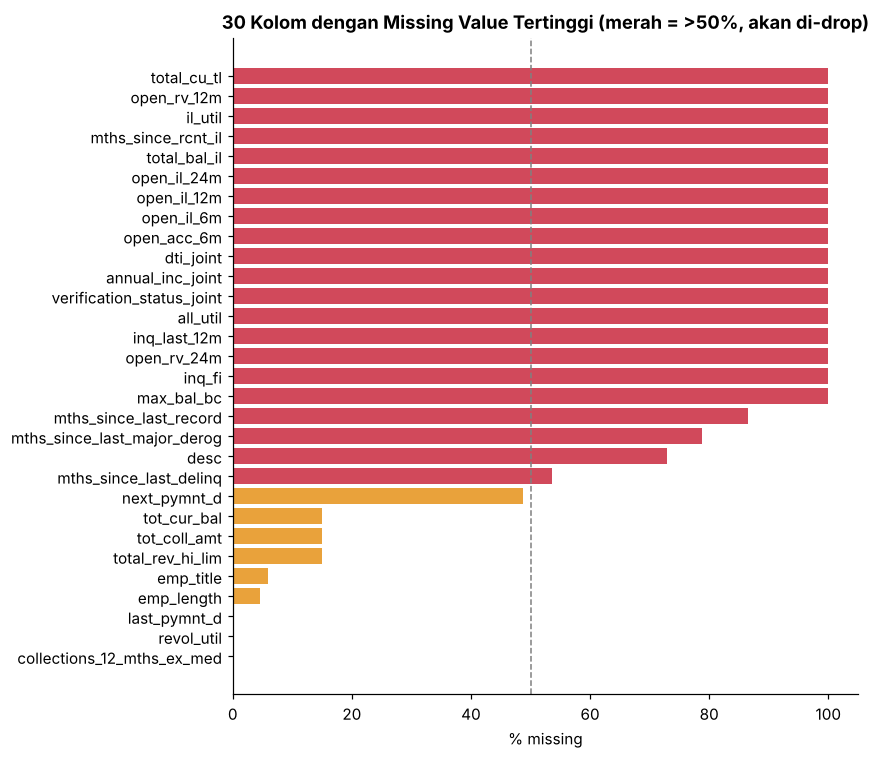

In [9]:
num_desc = df_raw[["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_util", "total_acc"]].describe().T
print(num_desc[["count", "mean", "std", "min", "50%", "max"]].round(2).to_string())

miss_pct = (df_raw.isnull().mean() * 100).sort_values(ascending=False)
print()
print(f"Kolom 100% kosong        : {(miss_pct == 100).sum()}")
print(f"Kolom missing > 50%      : {(miss_pct > 50).sum()} dari {df_raw.shape[1]}")
print(f"Kolom missing 1% - 50%   : {((miss_pct > 1) & (miss_pct <= 50)).sum()}")

top_miss = miss_pct[miss_pct > 0].head(30).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_miss.index, top_miss.values, color=np.where(top_miss.values > 50, BAD, ACCENT))
ax.axvline(50, ls="--", c="gray", lw=1)
ax.set_xlabel("% missing")
ax.set_title("30 Kolom dengan Missing Value Tertinggi (merah = >50%, akan di-drop)")
show("01_missing_values")

## 2. Penentuan Label (Good / Bad)

Kolom performa kredit adalah **`loan_status`**. Label ditentukan dari riwayat pembayaran:

| Kategori | loan_status | Alasan |
|---|---|---|
| **Bad (1)** | Charged Off, Default, Late (31-120 days), Does not meet the credit policy: Charged Off | Gagal bayar / keterlambatan berat |
| **Good (0)** | Fully Paid, Does not meet the credit policy: Fully Paid | Pinjaman lunas |
| **Dikeluarkan** | Current, In Grace Period, Late (16-30 days) | Hasil akhir pinjaman belum diketahui |

> **Apa yang dilakukan:** Menghitung sebaran `loan_status`, mendefinisikan status Bad dan Good, membuang pinjaman yang belum selesai, lalu membuat kolom `target` (1 = bad, 0 = good).
>
> **Kenapa:** Dataset tidak memiliki kolom label, jadi label harus dibuat dari kolom performa kredit, yaitu `loan_status`. Status Current, In Grace Period, dan Late 16-30 hari dikeluarkan karena hasil akhirnya belum diketahui. Memberi label pada pinjaman itu hanya menambah noise pada target.

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761

Baris awal            : 466,285
Baris dengan label    : 237,695  (dikeluarkan: 228,590 pinjaman yang belum selesai)
Good (0)              : 186,727  (78.56%)
Bad  (1)              : 50,968  (21.44%)

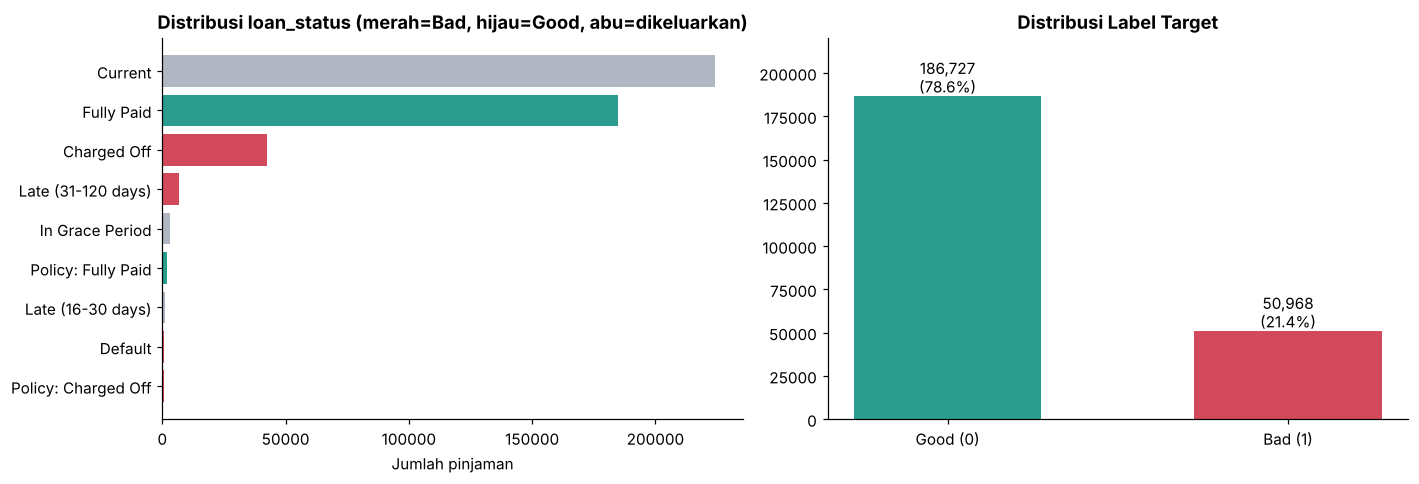

In [12]:
status_counts = df_raw["loan_status"].value_counts()
print(status_counts.to_string())

BAD_STATUS = ["Charged Off", "Default", "Late (31-120 days)", "Does not meet the credit policy. Status:Charged Off"]
GOOD_STATUS = ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]

df = df_raw[df_raw["loan_status"].isin(BAD_STATUS + GOOD_STATUS)].copy()
df["target"] = df["loan_status"].isin(BAD_STATUS).astype(int)

print()
print(f"Baris awal            : {len(df_raw):,}")
print(f"Baris dengan label    : {len(df):,}  (dikeluarkan: {len(df_raw) - len(df):,} pinjaman yang belum selesai)")
print(f"Good (0)              : {(df['target'] == 0).sum():,}  ({(df['target'] == 0).mean():.2%})")
print(f"Bad  (1)              : {(df['target'] == 1).sum():,}  ({(df['target'] == 1).mean():.2%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = status_counts.sort_values()
colors = [BAD if s in BAD_STATUS else GOOD if s in GOOD_STATUS else "#B0B7C3" for s in sc.index]
axes[0].barh([s.replace("Does not meet the credit policy. Status:", "Policy: ") for s in sc.index], sc.values, color=colors)
axes[0].set_title("Distribusi loan_status (merah=Bad, hijau=Good, abu=dikeluarkan)")
axes[0].set_xlabel("Jumlah pinjaman")
tc = df["target"].value_counts().sort_index()
bars = axes[1].bar(["Good (0)", "Bad (1)"], tc.values, color=[GOOD, BAD], width=0.55)
for b, v in zip(bars, tc.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / tc.sum():.1%})", ha="center", va="bottom")
axes[1].set_ylim(0, tc.max() * 1.18)
axes[1].set_title("Distribusi Label Target")
show("02_label_distribution")

## 3. Pembersihan Kolom: Leakage, Identitas, dan Kolom Kosong

Kolom yang **baru terisi setelah pinjaman berjalan** (pembayaran, sisa pokok, recoveries, dst.) tidak boleh
dipakai karena tidak tersedia saat keputusan kredit dibuat. Jika dipakai, model tampak sangat akurat tetapi
tidak berguna untuk menilai pemohon baru (*data leakage*).

> **Apa yang dilakukan:** Mengelompokkan kolom yang akan dibuang (leakage, identitas/teks, redundan, missing di atas 50%, konstan), mencetak jumlah tiap kelompok, lalu menghapusnya.
>
> **Kenapa:** Yang terpenting adalah **leakage**. Kolom seperti `total_pymnt` dan `recoveries` baru terisi setelah pinjaman berjalan atau gagal bayar. Jika dipakai, model seolah-olah sudah melihat jawabannya: AUC tinggi, tetapi tidak berguna untuk menilai pemohon baru. ID dan teks bebas tidak menggeneralisasi, sedangkan `funded_amnt` dan `sub_grade` hanya menduplikasi informasi `loan_amnt` dan `grade`.

In [15]:
LEAKAGE = ["out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int",
           "total_rec_late_fee", "recoveries", "collection_recovery_fee", "last_pymnt_d", "last_pymnt_amnt",
           "next_pymnt_d", "last_credit_pull_d"]
IDENT_TEXT = ["Unnamed: 0", "id", "member_id", "url", "desc", "title", "emp_title", "zip_code"]
REDUNDANT = ["funded_amnt", "funded_amnt_inv", "sub_grade"]   # sama informasinya dengan loan_amnt / grade

high_missing = [c for c in df.columns if df[c].isnull().mean() > 0.5]
constant = [c for c in df.columns if df[c].nunique(dropna=False) <= 1 and c not in high_missing]   # konstan tetapi terisi

drop_summary = pd.DataFrame({
    "Alasan": ["Leakage (post-origination)", "Identitas / teks bebas / kardinalitas tinggi", "Redundan",
               "Missing > 50% (termasuk yang 100% kosong)", "Konstanta (1 nilai, terisi)"],
    "Jumlah kolom": [len(LEAKAGE), len(IDENT_TEXT), len(REDUNDANT), len(high_missing), len(constant)]})
print(drop_summary.to_string(index=False))
print()
print("Konstanta:", constant)

to_drop = set(LEAKAGE + IDENT_TEXT + REDUNDANT + high_missing + constant)
keep_extra = {"loan_status", "target", "issue_d", "earliest_cr_line"}   # dipakai untuk label / feature engineering
df = df.drop(columns=[c for c in to_drop if c in df.columns and c not in keep_extra])
print(f"\nKolom tersisa: {df.shape[1]}")
print(list(df.columns))

                                      Alasan  Jumlah kolom
                  Leakage (post-origination)            13
Identitas / teks bebas / kardinalitas tinggi             8
                                    Redundan             3
   Missing > 50% (termasuk yang 100% kosong)            22
                 Konstanta (1 nilai, terisi)             2

Konstanta: ['policy_code', 'application_type']

Kolom tersisa: 30
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'target']

## 4. Exploratory Data Analysis (EDA)
### 4.1 Analisis univariat — distribusi variabel numerik

> **Apa yang dilakukan:** Menggambar histogram 8 fitur numerik (`annual_inc` dan `revol_bal` dalam skala log) beserta skewness-nya, lalu boxplot tiga fitur untuk melihat outlier.
>
> **Kenapa:** Ini analisis univariat, yaitu melihat bentuk distribusi satu variabel. Skewness tinggi dan outlier ekstrem menentukan perlakuan berikutnya: transformasi log dan winsorizing. Keduanya penting karena Logistic Regression sensitif terhadap nilai ekstrem.

Outlier ekstrem pada annual_inc, revol_bal, dti akan di-winsorize di tahap Data Preparation.

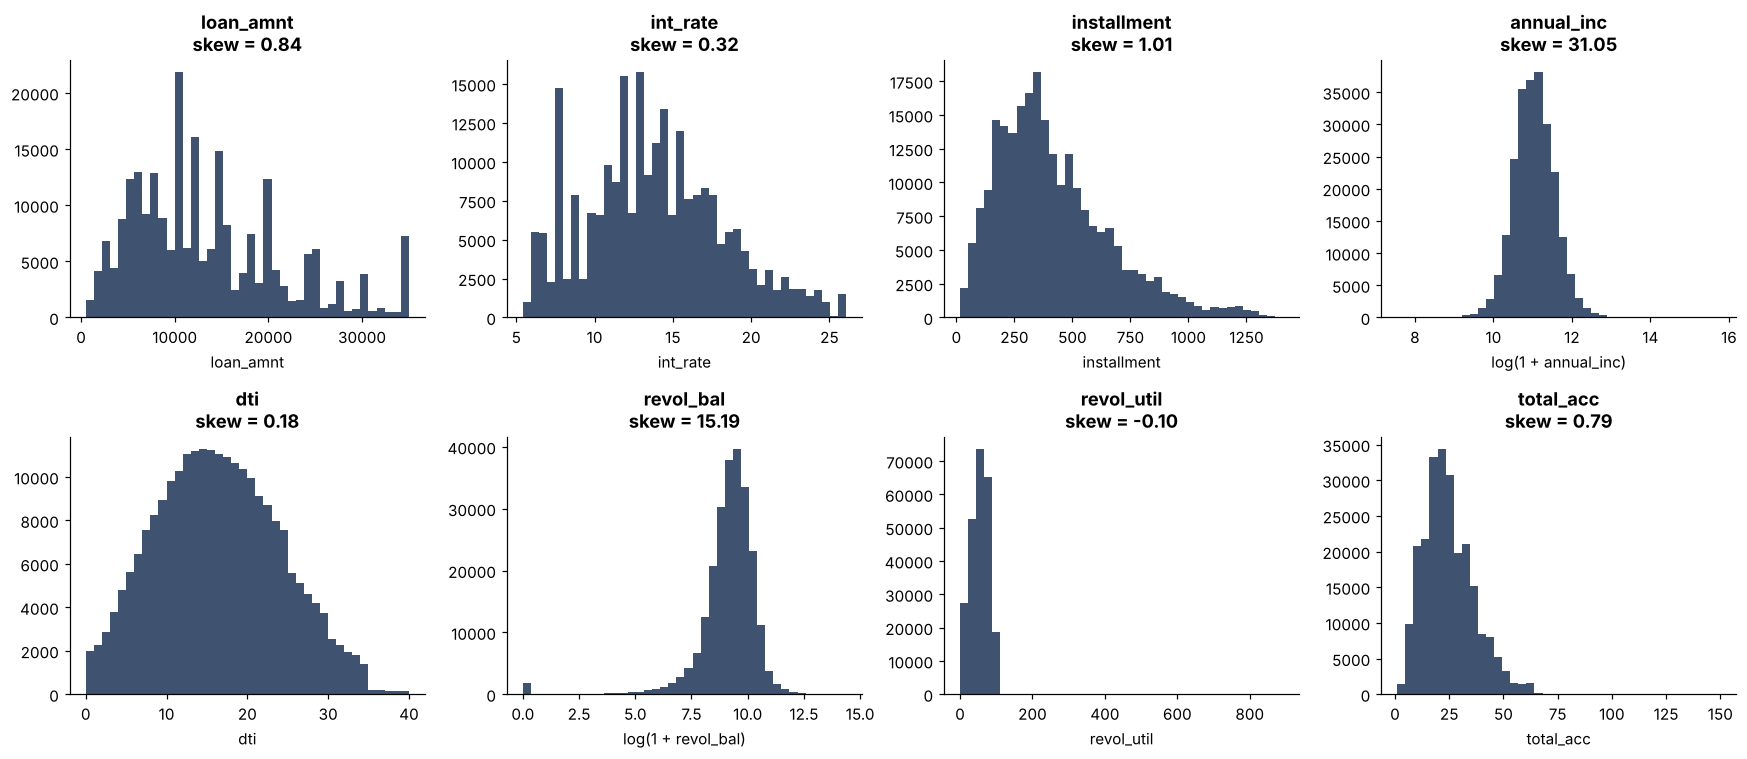

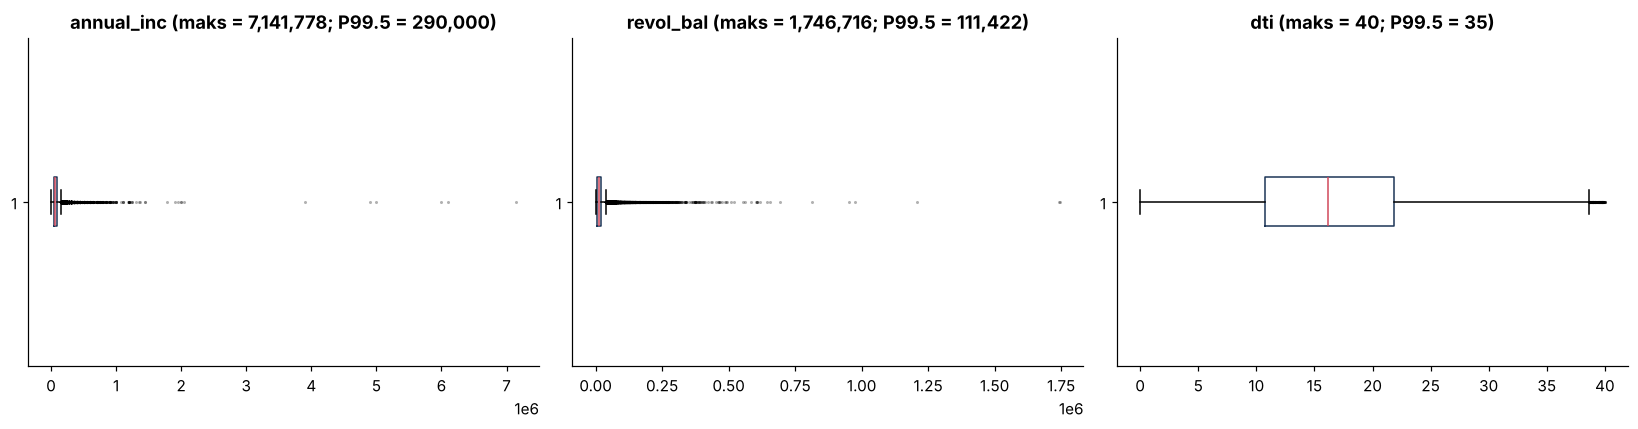

In [18]:
num_eda = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_bal", "revol_util", "total_acc"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_eda):
    s = df[c].dropna()
    if c in ("annual_inc", "revol_bal"):
        s = np.log1p(s)
        ax.set_xlabel(f"log(1 + {c})")
    else:
        ax.set_xlabel(c)
    ax.hist(s, bins=40, color=NAVY, alpha=0.85)
    ax.set_title(f"{c}\nskew = {df[c].skew():.2f}")
show("03_univariate_numeric")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["annual_inc", "revol_bal", "dti"]):
    ax.boxplot(df[c].dropna(), vert=False, flierprops=dict(marker=".", markersize=2, alpha=0.3),
               boxprops=dict(color=NAVY), medianprops=dict(color=BAD))
    q99 = df[c].quantile(0.995)
    ax.set_title(f"{c} (maks = {df[c].max():,.0f}; P99.5 = {q99:,.0f})")
show("04_outlier_boxplot")
print("Outlier ekstrem pada annual_inc, revol_bal, dti akan di-winsorize di tahap Data Preparation.")

### 4.2 Analisis bivariat — hubungan fitur kategorikal dengan risiko (bad rate)

> **Apa yang dilakukan:** Mendefinisikan fungsi untuk menggambar *bad rate* (persentase pinjaman bad) per kategori, lalu memakainya untuk grade, term, verification_status, home_ownership, purpose, dan addr_state. Garis putus-putus adalah rata-rata keseluruhan.
>
> **Kenapa:** Ini analisis bivariat: apakah suatu kategori membedakan risiko? Kategori dengan kurang dari 200 sampel diabaikan karena bad rate-nya tidak stabil. Bad rate yang naik teratur dari grade A (7,3%) ke G (47,0%) menunjukkan sinyal yang kuat.

Bad rate per grade (%): {'A': 7.3, 'B': 14.9, 'C': 23.7, 'D': 30.8, 'E': 38.9, 'F': 43.9, 'G': 47.0}

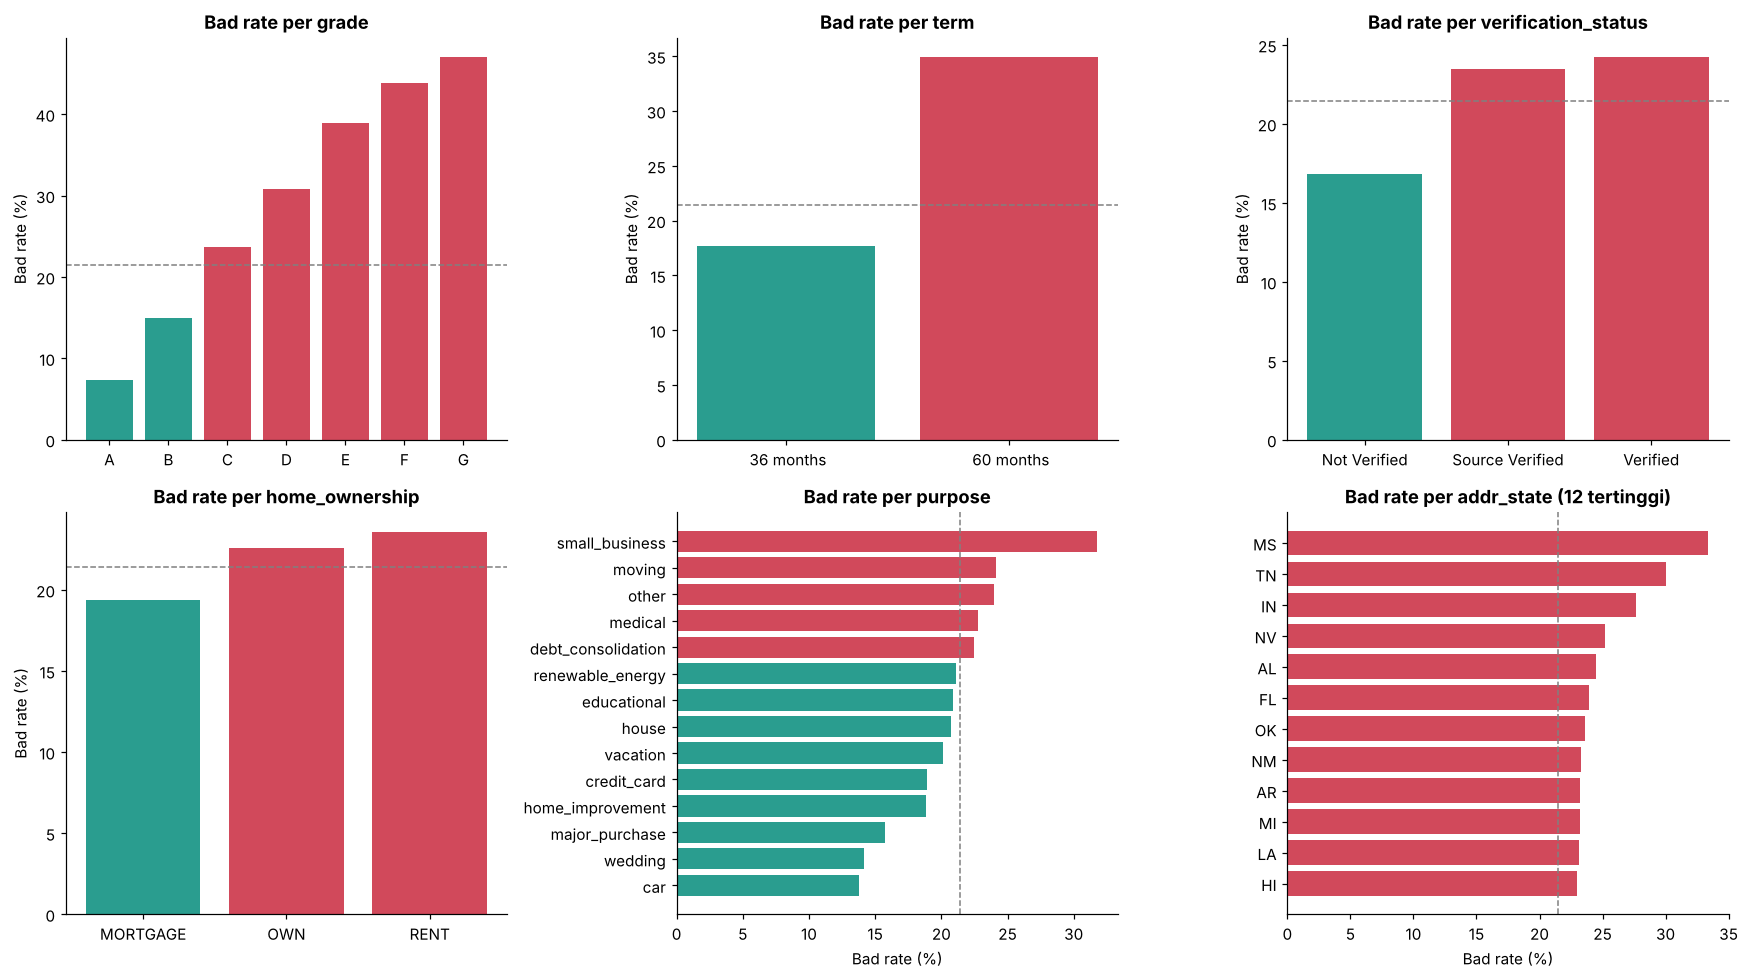

In [21]:
def bad_rate_bar(ax, col, order=None, horizontal=False, top=None):
    g = df.groupby(col)["target"].agg(["mean", "count"])
    g = g[g["count"] >= 200]
    g = g.sort_values("mean") if order is None else g.loc[[o for o in order if o in g.index]]
    if top:
        g = g.tail(top)
    colors = [BAD if v > df["target"].mean() else GOOD for v in g["mean"]]
    labels = [str(i) for i in g.index]
    (ax.barh if horizontal else ax.bar)(labels, g["mean"] * 100, color=colors)
    ax.axvline(df["target"].mean() * 100, color="gray", ls="--", lw=1) if horizontal else ax.axhline(df["target"].mean() * 100, color="gray", ls="--", lw=1)
    ax.set_title(f"Bad rate per {col}")
    ax.set_xlabel("Bad rate (%)") if horizontal else ax.set_ylabel("Bad rate (%)")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
bad_rate_bar(axes[0, 0], "grade", order=list("ABCDEFG"))
bad_rate_bar(axes[0, 1], "term")
bad_rate_bar(axes[0, 2], "verification_status")
bad_rate_bar(axes[1, 0], "home_ownership")
bad_rate_bar(axes[1, 1], "purpose", horizontal=True)
bad_rate_bar(axes[1, 2], "addr_state", horizontal=True, top=12)
axes[1, 2].set_title("Bad rate per addr_state (12 tertinggi)")
show("05_bivariate_categorical")

g = df.groupby("grade")["target"].mean() * 100
print("Bad rate per grade (%):", g.round(1).to_dict())

### 4.3 Analisis bivariat — fitur numerik berdasarkan Good vs Bad

> **Apa yang dilakukan:** Menggambar distribusi `int_rate`, `dti`, `revol_util`, dan `loan_amnt` secara terpisah untuk kelompok Good dan Bad, lalu mencetak median tiap kelompok.
>
> **Kenapa:** Memakai *density* (bukan jumlah mentah) supaya dua kelompok dengan ukuran sangat berbeda (78,6% vs 21,4%) tetap bisa dibandingkan bentuknya. Data dipotong di persentil 0,5 dan 99,5 agar outlier tidak merusak skala. Distribusi Bad yang bergeser ke kanan pada `int_rate` dan `dti` menandakan fitur tersebut diskriminatif.

Median per kelompok:
      int_rate    dti  revol_util  loan_amnt  annual_inc
Good     13.11  15.57        55.2    11625.0     64000.0
Bad      15.61  18.28        61.6    12800.0     56300.0

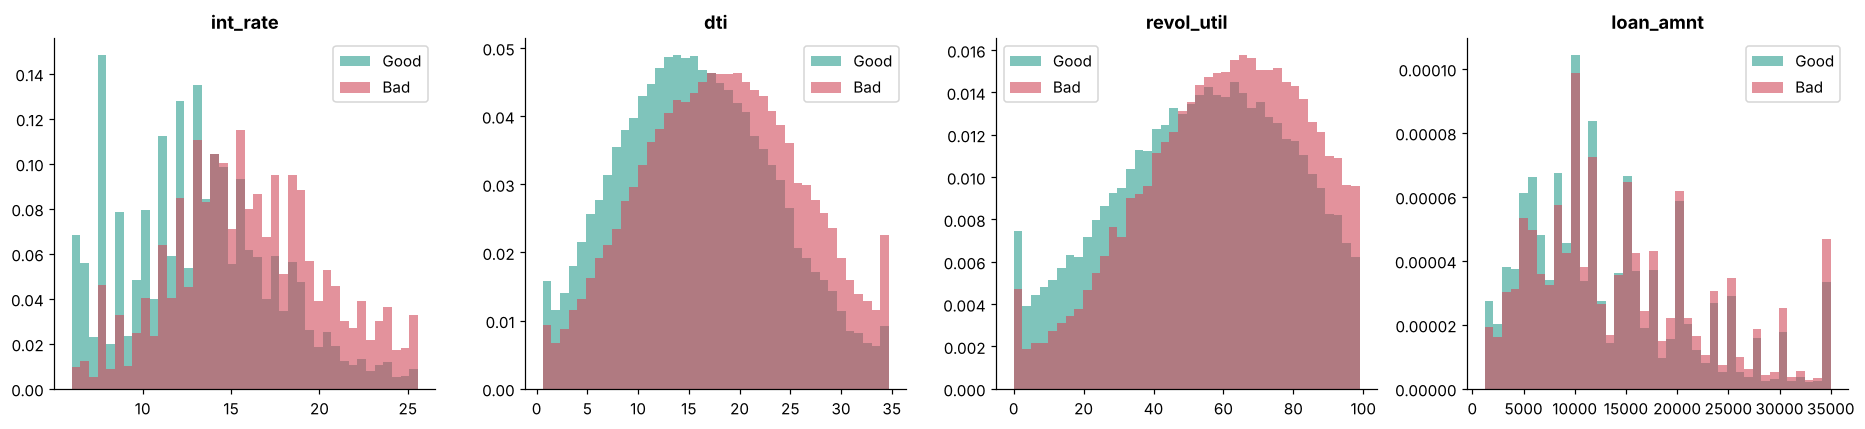

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["int_rate", "dti", "revol_util", "loan_amnt"]):
    lo, hi = df[c].quantile(0.005), df[c].quantile(0.995)
    for t, col, lab in [(0, GOOD, "Good"), (1, BAD, "Bad")]:
        ax.hist(df.loc[df["target"] == t, c].clip(lo, hi), bins=40, alpha=0.6, color=col, density=True, label=lab)
    ax.set_title(c)
    ax.legend()
show("06_bivariate_numeric")

cmp = df.groupby("target")[["int_rate", "dti", "revol_util", "loan_amnt", "annual_inc"]].median().round(2)
cmp.index = ["Good", "Bad"]
print("Median per kelompok:")
print(cmp.to_string())

### 4.4 Tren bad rate berdasarkan tahun penerbitan pinjaman

> **Apa yang dilakukan:** Mengubah `issue_d` menjadi tanggal, lalu menghitung jumlah pinjaman dan bad rate per tahun penerbitan.
>
> **Kenapa:** Untuk memeriksa apakah risiko stabil dari waktu ke waktu dan apakah ada bias pelabelan. Ternyata bad rate 2013-2014 tampak naik, tetapi itu karena hanya pinjaman yang sudah selesai yang berlabel. Jadi tren ini bukan penurunan kualitas kredit, dan temuan ini dicatat sebagai keterbatasan.

            count  bad_rate_pct
issue_year                     
2007          603          26.2
2008         2393          20.7
2009         5281          13.7
2010        12528          14.0
2011        19729          16.5
2012        49813          16.7
2013        73194          22.9
2014        74154          26.2

Catatan: hanya pinjaman yang sudah selesai (lunas / gagal bayar) yang berlabel. Pinjaman 2013-2014 yang berlabel
didominasi yang gagal bayar lebih awal, sebab pinjaman yang dilunasi penuh baru selesai setelah 2014 (bias kematangan).
Karena itu bad rate 2013-2014 tampak lebih tinggi dan tren ini tidak boleh dibaca sebagai penurunan kualitas kredit.

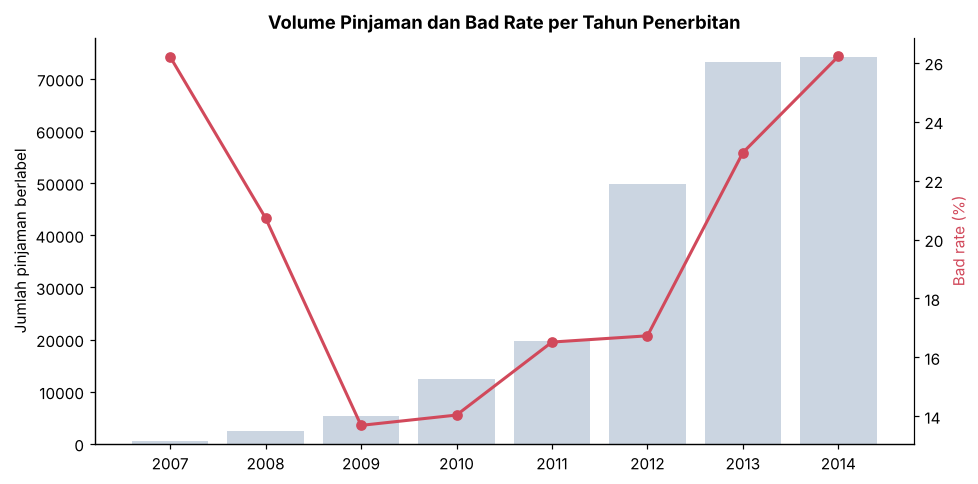

In [27]:
df["issue_dt"] = pd.to_datetime(df["issue_d"], format="%b-%y")
df["issue_year"] = df["issue_dt"].dt.year
yr = df.groupby("issue_year")["target"].agg(["mean", "count"])
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(yr.index, yr["count"], color="#CBD5E1")
ax1.set_ylabel("Jumlah pinjaman berlabel")
ax2 = ax1.twinx()
ax2.plot(yr.index, yr["mean"] * 100, color=BAD, marker="o", lw=2)
ax2.set_ylabel("Bad rate (%)", color=BAD)
ax2.spines["right"].set_visible(True)
ax1.set_title("Volume Pinjaman dan Bad Rate per Tahun Penerbitan")
show("07_trend_by_year")
print(yr.assign(bad_rate_pct=(yr["mean"] * 100).round(1))[["count", "bad_rate_pct"]].to_string())
print("\nCatatan: hanya pinjaman yang sudah selesai (lunas / gagal bayar) yang berlabel. Pinjaman 2013-2014 yang berlabel")
print("didominasi yang gagal bayar lebih awal, sebab pinjaman yang dilunasi penuh baru selesai setelah 2014 (bias kematangan).")
print("Karena itu bad rate 2013-2014 tampak lebih tinggi dan tren ini tidak boleh dibaca sebagai penurunan kualitas kredit.")

### 4.5 Analisis korelasi antar fitur numerik

> **Apa yang dilakukan:** Menghitung matriks korelasi fitur numerik, mengurutkannya menurut korelasi dengan target, menampilkan heatmap, dan mencetak pasangan fitur dengan korelasi mutlak di atas 0,8.
>
> **Kenapa:** Korelasi dengan target menunjukkan fitur yang paling relevan secara linear. Korelasi antar fitur (misalnya `loan_amnt` dan `installment`, 0,96) menandakan multikolinearitas yang bisa membuat koefisien Logistic Regression tidak stabil. Kedua fitur tetap dipakai karena regularisasi L2 meredam dampaknya, dan model berbasis pohon tidak terpengaruh.

Korelasi dengan target — 5 terendah:
tot_cur_bal        -0.077
annual_inc         -0.061
total_rev_hi_lim   -0.055
total_acc          -0.023
revol_bal          -0.002
Korelasi dengan target — 5 tertinggi:
inq_last_6mths    0.056
loan_amnt         0.073
revol_util        0.098
dti               0.127
int_rate          0.254

Pasangan fitur berkorelasi tinggi (|r| > 0.8):
  loan_amnt <-> installment: 0.96
  total_rev_hi_lim <-> revol_bal: 0.83

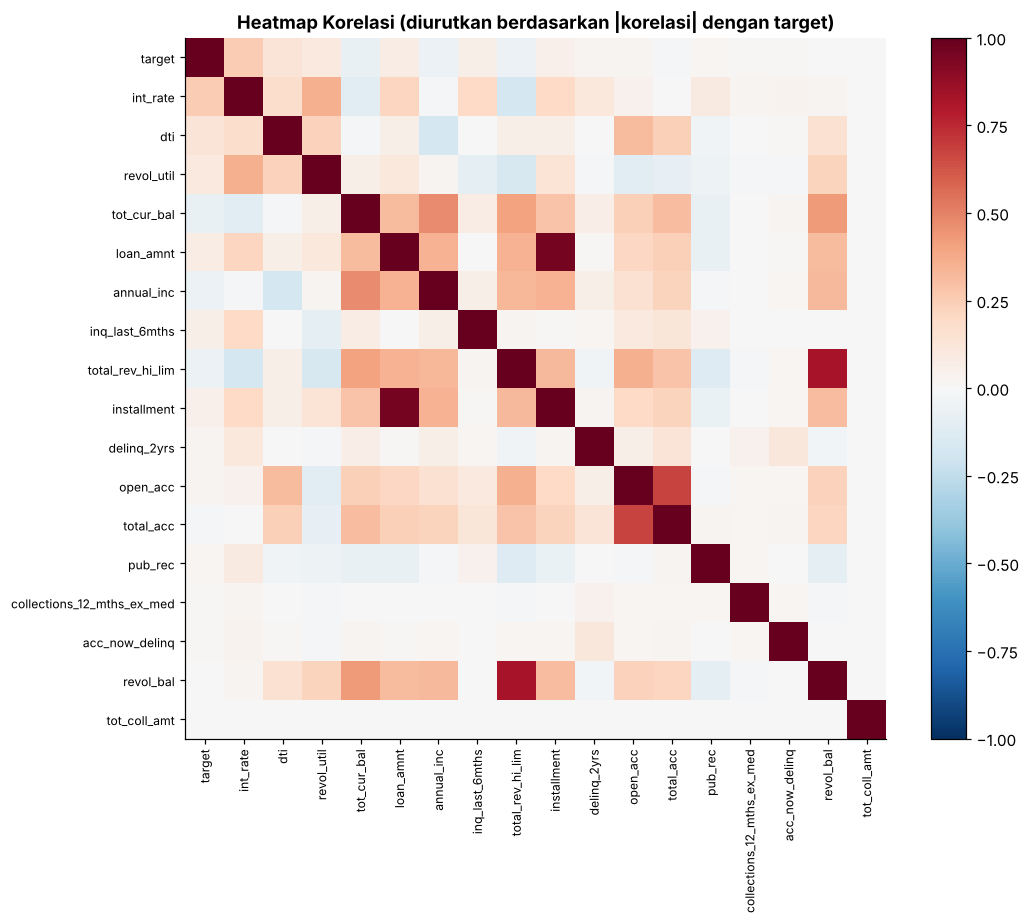

In [30]:
num_for_corr = df.select_dtypes(include=[np.number]).drop(columns=["issue_year"])
corr = num_for_corr.corr()
order = corr["target"].abs().sort_values(ascending=False).index
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, fraction=0.04)
ax.set_title("Heatmap Korelasi (diurutkan berdasarkan |korelasi| dengan target)")
show("08_correlation_heatmap")

tc = corr["target"].drop("target").sort_values()
print("Korelasi dengan target — 5 terendah:")
print(tc.head(5).round(3).to_string())
print("Korelasi dengan target — 5 tertinggi:")
print(tc.tail(5).round(3).to_string())

hi_pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("\nPasangan fitur berkorelasi tinggi (|r| > 0.8):")
for a, b, r in hi_pairs:
    print(f"  {a} <-> {b}: {r:.2f}")

## 5. Data Preparation
### 5.1 Feature engineering

> **Apa yang dilakukan:** Membuat fitur baru dan merapikan yang lama: `term` dan `emp_length` diubah menjadi angka, dihitung lama riwayat kredit, rasio pinjaman terhadap pendapatan, serta transformasi `log1p` pada fitur yang sangat skewed.
>
> **Kenapa:** Model hanya menerima angka, jadi teks seperti '36 months' harus diekstrak. Rasio terhadap pendapatan lebih mencerminkan kemampuan bayar dibanding nominal mentah. `log1p` memperpendek ekor kanan, dan `clip(lower=0)` mencegah error pada nilai negatif. Tahun dua digit pada `earliest_cr_line` dikoreksi karena '68' akan terbaca sebagai 2068.

In [33]:
def to_clean_features(d):
    d = d.copy()
    d["term_months"] = d["term"].str.extract(r"(\d+)").astype(float)
    emp = d["emp_length"].replace({"< 1 year": "0 years", "10+ years": "10 years", "n/a": np.nan})
    d["emp_length_yrs"] = emp.str.extract(r"(\d+)").astype(float)
    ecl = pd.to_datetime(d["earliest_cr_line"], format="%b-%y")
    ecl = ecl.where(ecl.dt.year <= 2014, ecl - pd.DateOffset(years=100))   # koreksi pivot tahun 2 digit
    d["credit_history_yrs"] = (d["issue_dt"] - ecl).dt.days / 365.25
    d["loan_to_income"] = (d["loan_amnt"] / d["annual_inc"]).replace([np.inf, -np.inf], np.nan)
    d["installment_to_income"] = (d["installment"] * 12 / d["annual_inc"]).replace([np.inf, -np.inf], np.nan)
    for c in ["annual_inc", "revol_bal", "tot_cur_bal", "total_rev_hi_lim", "tot_coll_amt"]:
        if c in d.columns:
            d[c] = np.log1p(d[c].clip(lower=0))   # transformasi log untuk distribusi sangat skewed
    return d.drop(columns=["term", "emp_length", "earliest_cr_line", "issue_d", "issue_dt", "issue_year", "loan_status"])

data = to_clean_features(df)
y = data.pop("target")
X = data
print(f"Fitur akhir: {X.shape[1]} kolom, {len(X):,} baris")
print("Fitur baru: term_months, emp_length_yrs, credit_history_yrs, loan_to_income, installment_to_income")
print("Transformasi log1p: annual_inc, revol_bal, tot_cur_bal, total_rev_hi_lim, tot_coll_amt")

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"\nKategorikal ({len(cat_cols)}): {cat_cols}")
print(f"Numerik ({len(num_cols)}): {num_cols}")

Fitur akhir: 29 kolom, 237,695 baris
Fitur baru: term_months, emp_length_yrs, credit_history_yrs, loan_to_income, installment_to_income
Transformasi log1p: annual_inc, revol_bal, tot_cur_bal, total_rev_hi_lim, tot_coll_amt

Kategorikal (7): ['grade', 'home_ownership', 'verification_status', 'pymnt_plan', 'purpose', 'addr_state', 'initial_list_status']
Numerik (22): ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'term_months', 'emp_length_yrs', 'credit_history_yrs', 'loan_to_income', 'installment_to_income']

### 5.2 Split data: train set dan test set (stratified 80 : 20)

Split dilakukan **sebelum** imputasi, winsorizing, scaling, dan encoding. Semua statistik transformasi dihitung
hanya dari train set di dalam `Pipeline`, sehingga tidak ada kebocoran informasi dari test set maupun dari
fold validasi saat cross-validation.

> **Apa yang dilakukan:** Membagi data menjadi train 80% dan test 20% secara *stratified*.
>
> **Kenapa:** Test set berfungsi sebagai ujian akhir yang tidak disentuh selama tuning. `stratify` menjaga bad rate tetap sama di kedua bagian (21,44%), penting untuk data imbalanced. Split dilakukan **sebelum** preprocessing agar tidak ada informasi test yang bocor ke proses training.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}  | bad rate {y_train.mean():.2%}")
print(f"Test : {X_test.shape}  | bad rate {y_test.mean():.2%}")

Train: (190156, 29)  | bad rate 21.44%
Test : (47539, 29)  | bad rate 21.44%

### 5.3 Pipeline preprocessing: outlier, missing value, scaling, encoding

> **Apa yang dilakukan:** Mendefinisikan transformer `Winsorizer` buatan sendiri, lalu menyusun `ColumnTransformer`: fitur numerik melewati winsorizing, imputasi median dengan indikator missing, dan scaling; fitur kategorikal di-one-hot.
>
> **Kenapa:** Semuanya dibungkus dalam `Pipeline` agar statistik (persentil, median, mean, kategori) hanya dihitung dari data train, juga di setiap fold saat cross-validation, sehingga tidak ada kebocoran. Median tahan terhadap outlier. Indikator missing menyimpan informasi bahwa nilainya kosong (misalnya `tot_cur_bal` kosong 28%). Scaling dibutuhkan karena regularisasi Logistic Regression sensitif terhadap skala. One-hot dipakai karena kategori tidak berurutan, dan kategori di bawah 0,5% digabung agar tidak muncul kolom yang hampir kosong.

In [39]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip nilai ke persentil bawah/atas yang dihitung dari data train."""
    def __init__(self, lower=0.5, upper=99.5):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cols_ = list(X.columns)
        self.lo_ = np.nanpercentile(X.values.astype(float), self.lower, axis=0)
        self.hi_ = np.nanpercentile(X.values.astype(float), self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.array(self.cols_)

def make_preprocess():
    num_pipe = Pipeline([("win", Winsorizer()),
                         ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("sc", StandardScaler())])
    cat_pipe = OneHotEncoder(handle_unknown="ignore", min_frequency=0.005, sparse_output=False)
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

Xt = make_preprocess().fit(X_train).transform(X_train)
print(f"Dimensi setelah preprocessing: {Xt.shape}  (missing value tersisa: {int(np.isnan(Xt).sum())})")
miss_cols = X_train[num_cols].isnull().mean()
print("\nKolom numerik dengan missing value di train (imputasi median + indikator missing):")
print((miss_cols[miss_cols > 0] * 100).round(1).sort_values(ascending=False).to_string())

Dimensi setelah preprocessing: (190156, 105)  (missing value tersisa: 0)

Kolom numerik dengan missing value di train (imputasi median + indikator missing):
tot_cur_bal                   28.0
total_rev_hi_lim              28.0
tot_coll_amt                  28.0
emp_length_yrs                 3.9
collections_12_mths_ex_med     0.1
revol_util                     0.1
annual_inc                     0.0
delinq_2yrs                    0.0
total_acc                      0.0
pub_rec                        0.0
inq_last_6mths                 0.0
open_acc                       0.0
acc_now_delinq                 0.0
credit_history_yrs             0.0
loan_to_income                 0.0
installment_to_income          0.0

## 6. Data Modelling

Dua algoritma dibandingkan secara adil: keduanya di-tuning dengan **cross-validation 3-fold** (metrik ROC-AUC).
Untuk efisiensi, pencarian hyperparameter dilakukan pada sampel 60.000 baris dari train set; model terbaik
kemudian dilatih ulang pada **seluruh** train set.

### 6.1 Model 1 — Logistic Regression (GridSearchCV)

> **Apa yang dilakukan:** Menjalankan `GridSearchCV` pada Logistic Regression dengan kombinasi `C` dan `class_weight` (3-fold CV, sampel 60.000 baris), lalu mencetak skor train dan skor CV.
>
> **Kenapa:** `C` mengatur kekuatan regularisasi (makin kecil makin kuat), sedangkan `class_weight='balanced'` menguji apakah pembobotan kelas minoritas membantu. Metrik ROC-AUC dipilih karena tidak bergantung pada threshold dan cocok untuk data imbalanced. Pencarian pada sampel mempercepat proses. Membandingkan AUC train dengan AUC CV membantu mendeteksi overfitting.

In [42]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=60000, stratify=y_train, random_state=RANDOM_STATE)

lr_pipe = Pipeline([("prep", make_preprocess()), ("clf", LogisticRegression(max_iter=500, solver="lbfgs"))])
lr_grid = {"clf__C": [0.01, 0.1, 1.0], "clf__class_weight": [None, "balanced"]}

t0 = time.time()
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="roc_auc", cv=cv, n_jobs=1, return_train_score=True)
lr_search.fit(X_tune, y_tune)
print(f"Waktu tuning: {time.time() - t0:.0f} detik")

res = pd.DataFrame(lr_search.cv_results_)[["param_clf__C", "param_clf__class_weight", "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["C", "class_weight", "AUC train", "AUC CV (mean)", "AUC CV (std)"]
res["class_weight"] = res["class_weight"].fillna("None").astype(str)
print(res.sort_values("AUC CV (mean)", ascending=False).round(4).to_string(index=False))
print("\nParameter terbaik:", lr_search.best_params_)
print(f"AUC CV terbaik   : {lr_search.best_score_:.4f}")

Waktu tuning: 12 detik
   C class_weight  AUC train  AUC CV (mean)  AUC CV (std)
0.01     balanced     0.7149         0.7120        0.0031
0.10         None     0.7156         0.7120        0.0035
0.10     balanced     0.7157         0.7120        0.0034
0.01         None     0.7146         0.7119        0.0031
1.00         None     0.7156         0.7119        0.0036
1.00     balanced     0.7157         0.7118        0.0035

Parameter terbaik: {'clf__C': 0.01, 'clf__class_weight': 'balanced'}
AUC CV terbaik   : 0.7120

### 6.2 Model 2 — HistGradientBoosting (RandomizedSearchCV)

Gradient boosting dipilih untuk menangkap hubungan non-linear dan interaksi antar fitur yang tidak bisa
ditangkap Logistic Regression.

> **Apa yang dilakukan:** Menjalankan `RandomizedSearchCV` pada HistGradientBoosting dengan 8 kombinasi dari 5 hyperparameter.
>
> **Kenapa:** Ruang pencarian penuhnya 162 kombinasi, terlalu besar untuk grid, sehingga random search menjelajahinya dengan sedikit percobaan. `early_stopping` menghentikan boosting saat skor validasi tidak membaik, mengurangi overfitting sekaligus waktu. `l2_regularization` dan `min_samples_leaf` membatasi kompleksitas pohon. Gradient boosting dipilih karena mampu menangkap hubungan non-linear dan interaksi antar fitur.

In [45]:
hgb_pipe = Pipeline([("prep", make_preprocess()),
                     ("clf", HistGradientBoostingClassifier(early_stopping=True, n_iter_no_change=15,
                                                            validation_fraction=0.15, random_state=RANDOM_STATE))])
hgb_dist = {"clf__learning_rate": [0.03, 0.05, 0.1],
            "clf__max_leaf_nodes": [15, 31, 63],
            "clf__min_samples_leaf": [20, 50, 100],
            "clf__l2_regularization": [0.0, 1.0, 10.0],
            "clf__max_iter": [200, 400]}

t0 = time.time()
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_dist, n_iter=8, scoring="roc_auc", cv=cv, n_jobs=1,
                                random_state=RANDOM_STATE, return_train_score=True)
hgb_search.fit(X_tune, y_tune)
print(f"Waktu tuning: {time.time() - t0:.0f} detik")

res = pd.DataFrame(hgb_search.cv_results_)
res = res[["param_clf__learning_rate", "param_clf__max_leaf_nodes", "param_clf__min_samples_leaf",
           "param_clf__l2_regularization", "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["lr", "leaves", "min_leaf", "l2", "AUC train", "AUC CV (mean)", "AUC CV (std)"]
print(res.sort_values("AUC CV (mean)", ascending=False).round(4).to_string(index=False))
print("\nParameter terbaik:", hgb_search.best_params_)
print(f"AUC CV terbaik   : {hgb_search.best_score_:.4f}")

Waktu tuning: 104 detik
  lr  leaves  min_leaf   l2  AUC train  AUC CV (mean)  AUC CV (std)
0.05      31       100 10.0     0.7705         0.7134        0.0021
0.03      15        50 10.0     0.7381         0.7130        0.0023
0.10      15       100  1.0     0.7504         0.7128        0.0022
0.03      15        50  1.0     0.7414         0.7126        0.0024
0.05      15       100  0.0     0.7437         0.7126        0.0021
0.10      31       100 10.0     0.7690         0.7118        0.0018
0.10      31        50  1.0     0.7777         0.7112        0.0023
0.10      63        20  0.0     0.8304         0.7064        0.0009

Parameter terbaik: {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 200, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 10.0}
AUC CV terbaik   : 0.7134

### 6.3 Latih ulang model terbaik pada seluruh train set

> **Apa yang dilakukan:** Menyalin konfigurasi terbaik dari tiap pencarian dan melatihnya ulang pada seluruh train set.
>
> **Kenapa:** Tuning dilakukan pada sampel 60.000 baris demi kecepatan. Model akhir sebaiknya memakai seluruh data train agar belajar semaksimal mungkin. `clone` memastikan model dilatih dari awal, bukan melanjutkan model sampel.

In [48]:
final_models = {}
for name, search in [("Logistic Regression", lr_search), ("HistGradientBoosting", hgb_search)]:
    t0 = time.time()
    m = clone(search.best_estimator_)
    m.fit(X_train, y_train)
    final_models[name] = m
    print(f"{name:22s} dilatih ulang pada {len(X_train):,} baris ({time.time() - t0:.0f} detik)")

Logistic Regression    dilatih ulang pada 190,156 baris (3 detik)
HistGradientBoosting   dilatih ulang pada 190,156 baris (26 detik)

## 7. Evaluation
### 7.1 Metrik pada test set terpisah + pemeriksaan overfitting

Selain AUC dan PR-AUC, dipakai metrik standar credit scoring: **KS statistic** (pemisahan maksimum antara
distribusi good dan bad) dan **Gini** (= 2·AUC − 1).

> **Apa yang dilakukan:** Menghitung AUC (CV, train, test), PR-AUC, KS, Gini, dan metrik klasifikasi pada threshold optimal, lalu memeriksa selisih AUC train vs test.
>
> **Kenapa:** AUC, KS, dan Gini adalah metrik standar credit scoring. PR-AUC melengkapinya untuk kelas minoritas (baseline acak = bad rate, 0,214). Accuracy sengaja tidak dijadikan metrik utama karena menyesatkan pada data imbalanced. Threshold dipilih yang memaksimalkan TPR dikurangi FPR (titik KS), bukan 0,5, karena 0,5 tidak cocok untuk data dengan 21% kelas positif. Selisih train-test yang besar menandakan overfitting.

In [51]:
def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return (tpr - fpr).max()

def best_threshold(y_true, p):
    """Threshold yang memaksimalkan Youden J (= titik KS)."""
    fpr, tpr, thr = roc_curve(y_true, p)
    return thr[np.argmax(tpr - fpr)]

rows, probs = [], {}
for name, m in final_models.items():
    p_tr, p_te = m.predict_proba(X_train)[:, 1], m.predict_proba(X_test)[:, 1]
    probs[name] = p_te
    thr = best_threshold(y_test, p_te)
    pred = (p_te >= thr).astype(int)
    cv_auc = (lr_search if name == "Logistic Regression" else hgb_search).best_score_
    rows.append({"Model": name, "AUC CV (tuning)": cv_auc, "AUC train": roc_auc_score(y_train, p_tr),
                 "AUC test": roc_auc_score(y_test, p_te), "PR-AUC test": average_precision_score(y_test, p_te),
                 "KS test": ks_stat(y_test, p_te), "Gini test": 2 * roc_auc_score(y_test, p_te) - 1,
                 "Threshold*": thr, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
metrics = pd.DataFrame(rows).set_index("Model")
print(metrics.round(4).T.to_string())
print("\n* Threshold = titik yang memaksimalkan (TPR - FPR) pada test set.")
print(f"Baseline PR-AUC acak = bad rate = {y_test.mean():.4f}")

print("\nPemeriksaan overfitting (selisih AUC train vs test):")
for name in metrics.index:
    gap = metrics.loc[name, "AUC train"] - metrics.loc[name, "AUC test"]
    verdict = "wajar" if gap < 0.03 else "ada indikasi overfitting ringan" if gap < 0.06 else "overfitting"
    print(f"  {name:22s}: gap = {gap:+.4f}  -> {verdict}")

Model            Logistic Regression  HistGradientBoosting
AUC CV (tuning)               0.7120                0.7134
AUC train                     0.7133                0.7395
AUC test                      0.7147                0.7197
PR-AUC test                   0.3997                0.4068
KS test                       0.3161                0.3221
Gini test                     0.4295                0.4393
Threshold*                    0.5061                0.2077
Accuracy                      0.6586                0.6459
Precision                     0.3447                0.3393
Recall                        0.6572                0.6875
F1                            0.4522                0.4544

* Threshold = titik yang memaksimalkan (TPR - FPR) pada test set.
Baseline PR-AUC acak = bad rate = 0.2144

Pemeriksaan overfitting (selisih AUC train vs test):
  Logistic Regression   : gap = -0.0014  -> wajar
  HistGradientBoosting  : gap = +0.0198  -> wajar

### 7.2 Kurva ROC dan Precision-Recall

> **Apa yang dilakukan:** Menggambar kurva ROC dan Precision-Recall kedua model pada test set.
>
> **Kenapa:** Kurva ROC menunjukkan kemampuan memisahkan good dari bad di semua threshold. Kurva Precision-Recall lebih jujur untuk kelas minoritas. Kedua kurva yang hampir berimpit menunjukkan bahwa kedua model berkinerja setara.

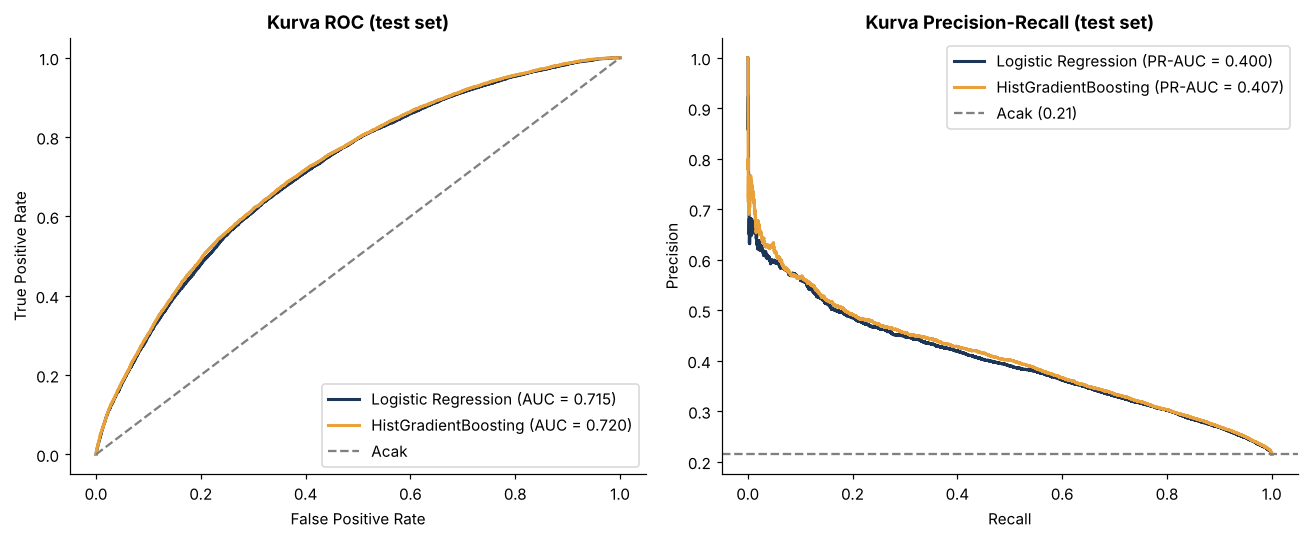

In [54]:
palette = {"Logistic Regression": NAVY, "HistGradientBoosting": ACCENT}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, color=palette[name], label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, lw=2, color=palette[name], label=f"{name} (PR-AUC = {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Acak")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate"); axes[0].set_title("Kurva ROC (test set)"); axes[0].legend()
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"Acak ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Kurva Precision-Recall (test set)"); axes[1].legend()
show("09_roc_pr_curves")

### 7.3 Confusion matrix dan analisis threshold (model terbaik)

> **Apa yang dilakukan:** Memilih model terbaik berdasarkan AUC test, menampilkan confusion matrix pada threshold 0,5 dan threshold optimal, lalu membuat tabel cutoff PD terhadap approval rate dan bad rate.
>
> **Kenapa:** Confusion matrix memperlihatkan jenis kesalahan model. Dalam kredit, meloloskan pinjaman bad itu mahal, tetapi menolak pinjaman good juga berarti kehilangan bisnis. Tabel cutoff menerjemahkan trade-off itu menjadi angka yang bisa dipilih manajemen sesuai risk appetite. Threshold 0,5 ditampilkan hanya sebagai pembanding.

Model terbaik berdasarkan AUC test: HistGradientBoosting

Trade-off kebijakan persetujuan: pinjaman dengan PD >= cutoff ditolak
 Cutoff PD  Approval rate  Bad rate (disetujui)  Bad tertangkap (recall)  Precision (ditolak)
      0.10          0.205                 0.062                    0.941                0.254
      0.15          0.393                 0.093                    0.830                0.293
      0.20          0.545                 0.116                    0.705                0.332
      0.25          0.666                 0.135                    0.582                0.373
      0.30          0.763                 0.153                    0.456                0.412
      0.40          0.893                 0.183                    0.238                0.477
      0.50          0.963                 0.201                    0.098                0.565

Bad rate keseluruhan (tanpa model) = 0.214

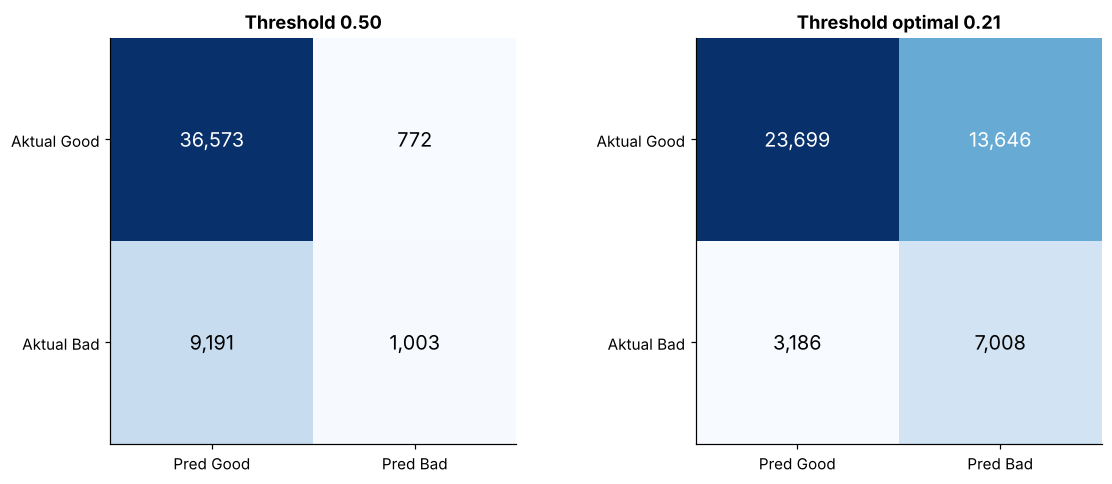

In [57]:
best_name = metrics["AUC test"].idxmax()
p_best = probs[best_name]
thr = metrics.loc[best_name, "Threshold*"]
print(f"Model terbaik berdasarkan AUC test: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, t) in zip(axes, [("Threshold 0.50", 0.5), (f"Threshold optimal {thr:.2f}", thr)]):
    cm = confusion_matrix(y_test, (p_best >= t).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred Good", "Pred Bad"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Aktual Good", "Aktual Bad"])
    ax.set_title(f"{title}")
show("10_confusion_matrix")

rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    approve = p_best < t
    rows.append({"Cutoff PD": t, "Approval rate": approve.mean(), "Bad rate (disetujui)": y_test[approve].mean(),
                 "Bad tertangkap (recall)": ((~approve) & (y_test == 1)).sum() / (y_test == 1).sum(),
                 "Precision (ditolak)": y_test[~approve].mean() if (~approve).any() else np.nan})
print("\nTrade-off kebijakan persetujuan: pinjaman dengan PD >= cutoff ditolak")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nBad rate keseluruhan (tanpa model) = {y_test.mean():.3f}")

### 7.4 Pemisahan risiko per desil dan kalibrasi probabilitas

> **Apa yang dilakukan:** Membagi test set menjadi 10 desil berdasarkan skor risiko, menghitung bad rate aktual, proporsi bad yang tertangkap, dan lift per desil, lalu menggambar kurva kalibrasi.
>
> **Kenapa:** Skor yang baik harus membuat bad rate turun teratur dari desil 1 ke desil 10. Tabel desil adalah format laporan standar credit scoring. Kalibrasi memeriksa apakah probabilitasnya bermakna (PD 30% memang berarti sekitar 30% bad), yang penting bila skor dipakai untuk penentuan bunga atau cadangan kerugian.

Tabel desil risiko — HistGradientBoosting (desil 1 = risiko tertinggi)
           n  avg_pred_PD  actual_bad_rate  bads  cum_bad_captured   lift
decile                                                                   
1       4754        0.490            0.481  2288             0.224  2.244
2       4754        0.362            0.375  1784             0.399  1.750
3       4754        0.293            0.308  1464             0.543  1.436
4       4754        0.243            0.231  1098             0.651  1.077
5       4754        0.202            0.203   965             0.745  0.947
6       4753        0.168            0.170   806             0.825  0.791
7       4754        0.138            0.142   677             0.891  0.664
8       4754        0.112            0.111   526             0.943  0.516
9       4754        0.085            0.080   382             0.980  0.375
10      4754        0.050            0.043   204             1.000  0.200

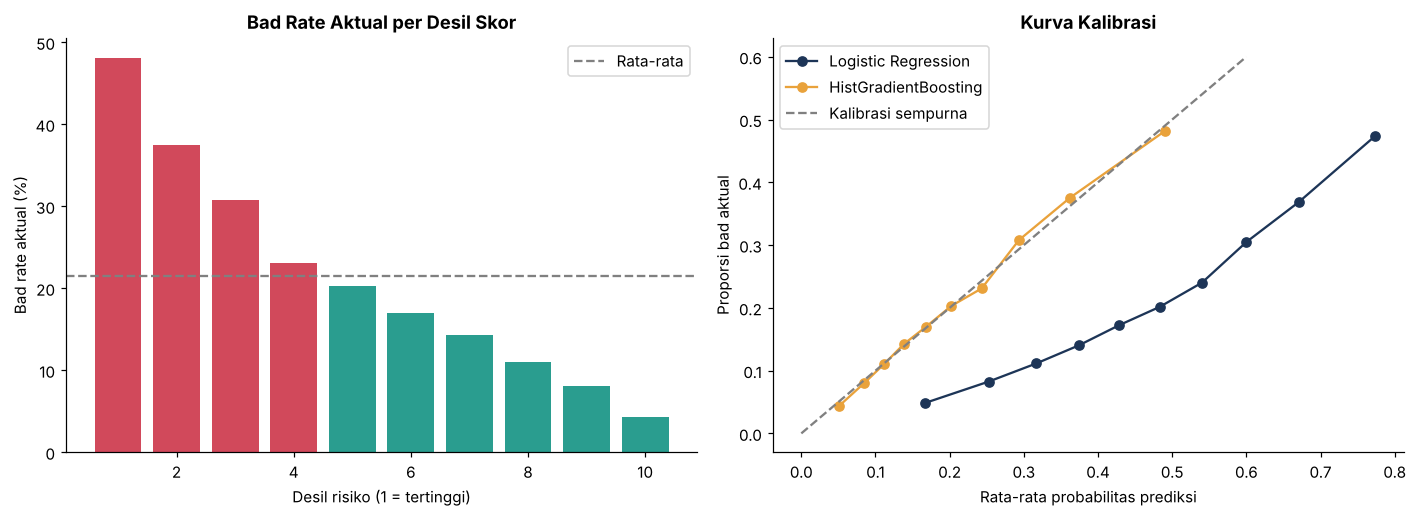

In [60]:
dec = pd.DataFrame({"p": p_best, "y": y_test.values})
dec["decile"] = pd.qcut(dec["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
tab = dec.groupby("decile").agg(n=("y", "size"), avg_pred_PD=("p", "mean"), actual_bad_rate=("y", "mean"), bads=("y", "sum"))
tab["cum_bad_captured"] = tab["bads"].cumsum() / tab["bads"].sum()
tab["lift"] = tab["actual_bad_rate"] / y_test.mean()
print(f"Tabel desil risiko — {best_name} (desil 1 = risiko tertinggi)")
print(tab.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(tab.index.astype(int), tab["actual_bad_rate"] * 100, color=[BAD if v > y_test.mean() else GOOD for v in tab["actual_bad_rate"]])
axes[0].axhline(y_test.mean() * 100, ls="--", color="gray", label="Rata-rata")
axes[0].set_xlabel("Desil risiko (1 = tertinggi)"); axes[0].set_ylabel("Bad rate aktual (%)")
axes[0].set_title("Bad Rate Aktual per Desil Skor"); axes[0].legend()
for name, p in probs.items():
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac, marker="o", color=palette[name], label=name)
axes[1].plot([0, 0.6], [0, 0.6], "--", color="gray", label="Kalibrasi sempurna")
axes[1].set_xlabel("Rata-rata probabilitas prediksi"); axes[1].set_ylabel("Proporsi bad aktual")
axes[1].set_title("Kurva Kalibrasi"); axes[1].legend()
show("11_decile_calibration")

### 7.5 Feature importance — faktor apa yang mendorong risiko?

> **Apa yang dilakukan:** Menampilkan koefisien Logistic Regression (10 terkecil dan 10 terbesar) dan *permutation importance* untuk HistGradientBoosting pada 15.000 sampel test.
>
> **Kenapa:** Fitur sudah di-scale, sehingga koefisien Logistic Regression bisa dibandingkan dan arahnya menjelaskan apakah fitur menaikkan atau menurunkan risiko. Permutation importance berlaku untuk model apa pun: satu fitur diacak, lalu diukur penurunan AUC-nya. Perhitungan memakai test set agar mencerminkan kegunaan nyata. Perlu diingat bahwa fitur yang saling berkorelasi (mis. `grade` dan `int_rate`) membagi kontribusinya.

Top 8 fitur (permutation importance, HistGradientBoosting):
int_rate          0.0681
term_months       0.0125
annual_inc        0.0097
loan_to_income    0.0085
dti               0.0076
open_acc          0.0042
total_acc         0.0039
purpose           0.0037

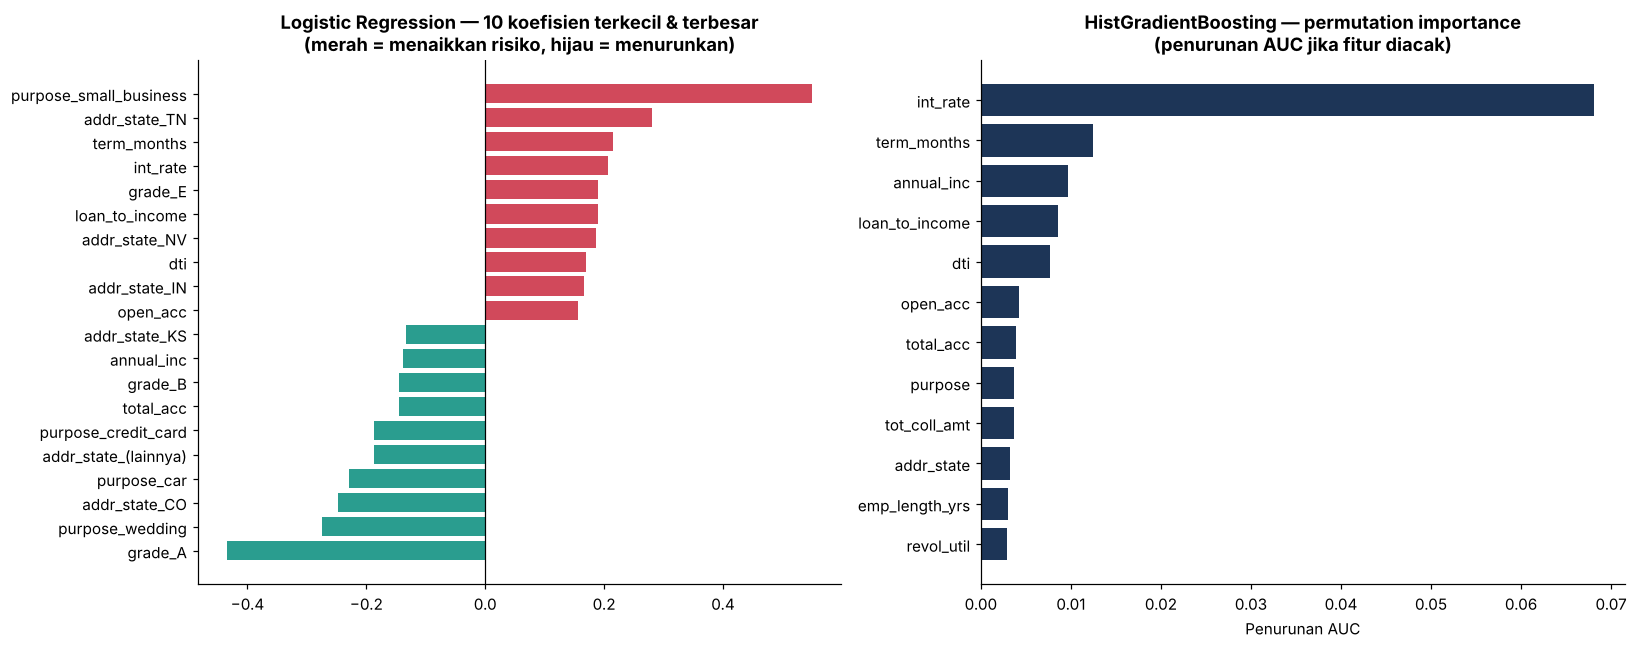

In [63]:
lr_final = final_models["Logistic Regression"]
names = [n.replace("_infrequent_sklearn", "_(lainnya)") for n in lr_final.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(lr_final.named_steps["clf"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh([n.replace("num__", "").replace("cat__", "") for n in top.index], top.values, color=[GOOD if v < 0 else BAD for v in top.values])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Logistic Regression — 10 koefisien terkecil & terbesar\n(merah = menaikkan risiko, hijau = menurunkan)")

samp = X_test.sample(15000, random_state=RANDOM_STATE)
imp = permutation_importance(final_models["HistGradientBoosting"], samp, y_test.loc[samp.index], scoring="roc_auc",
                             n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp_s = pd.Series(imp.importances_mean, index=samp.columns).sort_values().tail(12)
axes[1].barh(imp_s.index, imp_s.values, color=NAVY)
axes[1].set_title("HistGradientBoosting — permutation importance\n(penurunan AUC jika fitur diacak)")
axes[1].set_xlabel("Penurunan AUC")
show("12_feature_importance")
print("Top 8 fitur (permutation importance, HistGradientBoosting):")
print(imp_s.tail(8).iloc[::-1].round(4).to_string())

## 8. Kesimpulan dan Rekomendasi

> **Apa yang dilakukan:** Mengumpulkan angka kunci dari hasil run dan mencetak ringkasan serta rekomendasi.
>
> **Kenapa:** Angka diambil langsung dari variabel hasil eksekusi (bukan diketik manual) agar ringkasan selalu konsisten dengan hasil model.

In [66]:
lr_m, hg_m = metrics.loc["Logistic Regression"], metrics.loc["HistGradientBoosting"]
top_decile = tab.loc[1, "actual_bad_rate"]; low_decile = tab.loc[10, "actual_bad_rate"]
print("RINGKASAN HASIL")
print("-" * 70)
print(f"Data berlabel             : {len(X):,} pinjaman | bad rate {y.mean():.1%}")
print(f"Logistic Regression       : AUC test {lr_m['AUC test']:.3f} | KS {lr_m['KS test']:.3f} | Gini {lr_m['Gini test']:.3f}")
print(f"HistGradientBoosting      : AUC test {hg_m['AUC test']:.3f} | KS {hg_m['KS test']:.3f} | Gini {hg_m['Gini test']:.3f}")
print(f"Model terbaik             : {best_name}")
print(f"Bad rate desil 1 vs 10    : {top_decile:.1%} vs {low_decile:.1%}  ({top_decile / max(low_decile, 1e-9):.1f}x lipat)")
print(f"Desil 1-3 menangkap       : {tab.loc[3, 'cum_bad_captured']:.0%} dari seluruh bad loan")
print("-" * 70)
print("""
Rekomendasi:
1. Gunakan skor PD model sebagai alat bantu keputusan kredit (credit scoring), bukan keputusan otomatis tunggal.
2. Terapkan kebijakan bertingkat: PD rendah -> setujui, PD menengah -> review manual, PD tinggi -> tolak / suku bunga lebih tinggi.
3. Pilih cutoff berdasarkan trade-off approval rate vs bad rate (lihat tabel 7.3) dan biaya kredit macet bisnis.
4. Logistic Regression cocok untuk kebutuhan explainability/regulasi; gradient boosting untuk akurasi maksimum.
5. Pantau model secara berkala (drift, kalibrasi). Label bersifat right-censored sehingga model perlu dilatih ulang saat pinjaman 2013-2014 sudah matang.

Keterbatasan: label hanya dari pinjaman yang sudah selesai (pinjaman 'Current' dikeluarkan) sehingga ada bias kematangan,
data hanya berisi pinjaman yang disetujui (reject inference tidak dilakukan), validasi memakai split acak (bukan out-of-time),
dan tuning dilakukan pada sampel 60.000 baris.
""")

RINGKASAN HASIL
----------------------------------------------------------------------
Data berlabel             : 237,695 pinjaman | bad rate 21.4%
Logistic Regression       : AUC test 0.715 | KS 0.316 | Gini 0.429
HistGradientBoosting      : AUC test 0.720 | KS 0.322 | Gini 0.439
Model terbaik             : HistGradientBoosting
Bad rate desil 1 vs 10    : 48.1% vs 4.3%  (11.2x lipat)
Desil 1-3 menangkap       : 54% dari seluruh bad loan
----------------------------------------------------------------------

Rekomendasi:
1. Gunakan skor PD model sebagai alat bantu keputusan kredit (credit scoring), bukan keputusan otomatis tunggal.
2. Terapkan kebijakan bertingkat: PD rendah -> setujui, PD menengah -> review manual, PD tinggi -> tolak / suku bunga lebih tinggi.
3. Pilih cutoff berdasarkan trade-off approval rate vs bad rate (lihat tabel 7.3) dan biaya kredit macet bisnis.
4. Logistic Regression cocok untuk kebutuhan explainability/regulasi; gradient boosting untuk akurasi maksimum.
5.